In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split, ConcatDataset
from torchvision import datasets, transforms

import matplotlib.pyplot as plt
from torch.utils.data import Subset, ConcatDataset
from torchvision import datasets, transforms

In [2]:
# 시드 고정 및 실행위한 세팅 준비
seed = 42
torch.manual_seed(seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
batch_size = 64
epochs = 10
lr = 0.01

transform = transforms.ToTensor()
train_set_official = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
test_set_official  = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

100%|██████████| 26.4M/26.4M [00:03<00:00, 8.53MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 146kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.71MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 14.7MB/s]


In [3]:
full_dataset = ConcatDataset([train_set_official, test_set_official])
n_total = len(full_dataset)
n_train = int(0.8 * n_total)
n_val   = int(0.1 * n_total)
n_test  = n_total - n_train - n_val
train_ds, val_ds, test_ds = random_split(full_dataset, [n_train, n_val, n_test], generator=torch.Generator().manual_seed(seed))

In [4]:
X_train_all = torch.stack([train_ds[i][0] for i in range(len(train_ds))])
y_train_all = torch.tensor([train_ds[i][1] for i in range(len(train_ds))])

X_val_all   = torch.stack([val_ds[i][0] for i in range(len(val_ds))])
y_val_all   = torch.tensor([val_ds[i][1] for i in range(len(val_ds))])

X_test_all  = torch.stack([test_ds[i][0] for i in range(len(test_ds))])
y_test_all  = torch.tensor([test_ds[i][1] for i in range(len(test_ds))])

X_train_all, y_train_all = X_train_all.to(device), y_train_all.to(device)
X_val_all,   y_val_all   = X_val_all.to(device),   y_val_all.to(device)
X_test_all,  y_test_all  = X_test_all.to(device),  y_test_all.to(device)

In [5]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 10)
        )
    def forward(self, x):
        return self.net(x)

In [6]:
model = MLP().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

for epoch in range(1, epochs + 1):
    model.train()
    optimizer.zero_grad()

    logits = model(X_train_all)
    loss = criterion(logits, y_train_all)
    loss.backward()
    optimizer.step()

    with torch.no_grad():
        train_acc = (logits.argmax(1) == y_train_all).float().mean().item()

        model.eval()
        val_logits = model(X_val_all)
        val_acc = (val_logits.argmax(1) == y_val_all).float().mean().item()

    print(f"[Epoch {epoch:02d}] Train Acc: {train_acc*100:5.2f}% | Val Acc: {val_acc*100:5.2f}%")

model.eval()
with torch.no_grad():
    test_acc = (model(X_test_all).argmax(1) == y_test_all).float().mean().item()
print(f"\n=== Final Test Accuracy: {test_acc*100:5.2f}% ===")

[Epoch 01] Train Acc: 16.75% | Val Acc: 17.56%
[Epoch 02] Train Acc: 17.74% | Val Acc: 18.44%
[Epoch 03] Train Acc: 18.63% | Val Acc: 19.29%
[Epoch 04] Train Acc: 19.45% | Val Acc: 20.09%
[Epoch 05] Train Acc: 20.14% | Val Acc: 20.86%
[Epoch 06] Train Acc: 20.72% | Val Acc: 21.39%
[Epoch 07] Train Acc: 21.27% | Val Acc: 21.87%
[Epoch 08] Train Acc: 21.79% | Val Acc: 22.13%
[Epoch 09] Train Acc: 22.27% | Val Acc: 22.76%
[Epoch 10] Train Acc: 22.66% | Val Acc: 23.27%

=== Final Test Accuracy: 23.37% ===


In [7]:
# Dataloader 생성
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, pin_memory=True)

In [8]:
torch.manual_seed(seed)
model = MLP().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

for epoch in range(epochs):
    model.train()
    train_correct, train_total = 0, 0
    for X_train, y_train in train_loader:
        X_train, y_train = X_train.to(device), y_train.to(device)
        optimizer.zero_grad()
        pred = model(X_train)
        loss = criterion(pred, y_train)
        loss.backward()
        optimizer.step()
        train_correct += (pred.argmax(1) == y_train).sum().item()
        train_total   += y_train.size(0)
    train_acc = train_correct / train_total
    model.eval()
    val_correct, val_total = 0, 0
    with torch.no_grad():
        for X_val, y_val in val_loader:
            X_val, y_val = X_val.to(device), y_val.to(device)
            pred = model(X_val)
            val_correct += (pred.argmax(1) == y_val).sum().item()
            val_total   += y_val.size(0)
    val_acc = val_correct / val_total
    print(f"[Epoch {epoch:02d}] Train Acc: {train_acc*100:>5.2f}% | Val Acc: {val_acc*100:>5.2f}%")
model.eval()
test_correct, test_total = 0, 0
with torch.no_grad():
    for X_test, y_test in test_loader:
        X_test, y_test = X_test.to(device), y_test.to(device)
        pred = model(X_test)
        test_correct += (pred.argmax(1) == y_test).sum().item()
        test_total   += y_test.size(0)
test_acc = test_correct / test_total
print(f"\n=== Final Test Accuracy: {test_acc*100:>5.2f}% ===")

[Epoch 00] Train Acc: 60.12% | Val Acc: 71.00%
[Epoch 01] Train Acc: 75.12% | Val Acc: 77.67%
[Epoch 02] Train Acc: 79.80% | Val Acc: 80.17%
[Epoch 03] Train Acc: 81.60% | Val Acc: 82.31%
[Epoch 04] Train Acc: 82.52% | Val Acc: 83.04%
[Epoch 05] Train Acc: 83.48% | Val Acc: 82.94%
[Epoch 06] Train Acc: 83.95% | Val Acc: 82.86%
[Epoch 07] Train Acc: 84.30% | Val Acc: 84.39%
[Epoch 08] Train Acc: 84.76% | Val Acc: 84.00%
[Epoch 09] Train Acc: 85.12% | Val Acc: 84.69%

=== Final Test Accuracy: 84.60% ===


In [9]:
torch.manual_seed(seed)
model = MLP().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

train_losses, val_losses = [], []

for epoch in range(epochs):
    model.train()
    train_correct, train_total = 0, 0
    loss_sum, count = 0.0, 0

    for X_train, y_train in train_loader:
        X_train, y_train = X_train.to(device), y_train.to(device)
        optimizer.zero_grad()
        pred = model(X_train)
        loss = criterion(pred, y_train)
        loss.backward()
        optimizer.step()

        loss_sum += loss.item() * y_train.size(0)
        count    += y_train.size(0)

    train_losses.append(loss_sum / count)

    model.eval()
    val_correct, val_total = 0, 0
    vloss_sum, vcount = 0.0, 0
    with torch.no_grad():
        for X_val, y_val in val_loader:
            X_val, y_val = X_val.to(device), y_val.to(device)
            pred = model(X_val)
            vloss_sum += criterion(pred, y_val).item() * y_val.size(0)
            vcount    += y_val.size(0)
            val_correct += (pred.argmax(1) == y_val).sum().item()
            val_total   += y_val.size(0)

    val_losses.append(vloss_sum / vcount)
    print(f"[Epoch {epoch:02d}]  | "
          f"| Train Loss: {train_losses[-1]:.4f} | Val Loss: {val_losses[-1]:.4f}")

[Epoch 00]  | | Train Loss: 1.3425 | Val Loss: 0.8124
[Epoch 01]  | | Train Loss: 0.7006 | Val Loss: 0.6377
[Epoch 02]  | | Train Loss: 0.5865 | Val Loss: 0.5704
[Epoch 03]  | | Train Loss: 0.5291 | Val Loss: 0.5198
[Epoch 04]  | | Train Loss: 0.4956 | Val Loss: 0.4915
[Epoch 05]  | | Train Loss: 0.4739 | Val Loss: 0.4943
[Epoch 06]  | | Train Loss: 0.4585 | Val Loss: 0.4822
[Epoch 07]  | | Train Loss: 0.4459 | Val Loss: 0.4505
[Epoch 08]  | | Train Loss: 0.4344 | Val Loss: 0.4544
[Epoch 09]  | | Train Loss: 0.4244 | Val Loss: 0.4358


[Train-split stats] mean=0.2859, std=0.3529
[Norm] Epoch 00 | Train Loss: 0.8441 | Val Loss: 0.5618
[Norm] Epoch 01 | Train Loss: 0.4989 | Val Loss: 0.4709
[Norm] Epoch 02 | Train Loss: 0.4435 | Val Loss: 0.4435
[Norm] Epoch 03 | Train Loss: 0.4125 | Val Loss: 0.4180
[Norm] Epoch 04 | Train Loss: 0.3906 | Val Loss: 0.3970
[Norm] Epoch 05 | Train Loss: 0.3729 | Val Loss: 0.4083
[Norm] Epoch 06 | Train Loss: 0.3595 | Val Loss: 0.3801
[Norm] Epoch 07 | Train Loss: 0.3474 | Val Loss: 0.3623
[Norm] Epoch 08 | Train Loss: 0.3364 | Val Loss: 0.3589
[Norm] Epoch 09 | Train Loss: 0.3265 | Val Loss: 0.3510


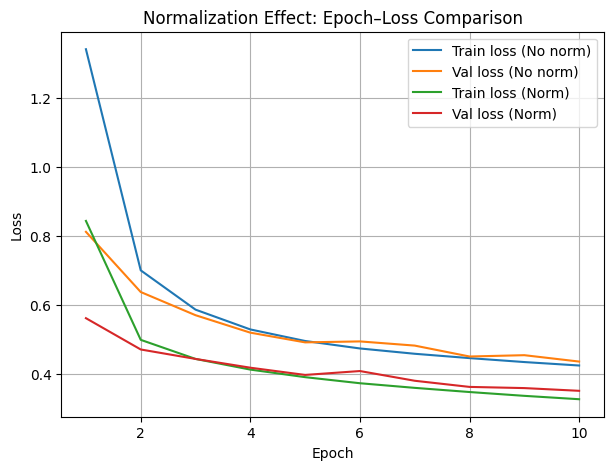

In [10]:
train_idx, val_idx, test_idx = train_ds.indices, val_ds.indices, test_ds.indices
n0 = len(train_set_official)
idx0 = [i for i in train_idx if i < n0]
idx1 = [i - n0 for i in train_idx if i >= n0]
train_pixels = torch.cat([
    train_set_official.data[idx0],
    test_set_official.data[idx1],
], dim=0).float()
mean = (train_pixels.mean() / 255.0).item()
std  = (train_pixels.std()  / 255.0).item()
print(f"[Train-split stats] mean={mean:.4f}, std={std:.4f}")
transform_norm = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([mean], [std]),
])
norm_full = ConcatDataset([
    datasets.FashionMNIST("./data", train=True,  download=True, transform=transform_norm),
    datasets.FashionMNIST("./data", train=False, download=True, transform=transform_norm),
])
norm_train = Subset(norm_full, train_idx)
norm_val   = Subset(norm_full, val_idx)
norm_test  = Subset(norm_full, test_idx)
norm_train_loader = DataLoader(norm_train, batch_size=batch_size, shuffle=True,  pin_memory=True)
norm_val_loader   = DataLoader(norm_val,   batch_size=batch_size, shuffle=False, pin_memory=True)
norm_test_loader  = DataLoader(norm_test,  batch_size=batch_size, shuffle=False, pin_memory=True)
torch.manual_seed(seed)
model = MLP().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

train_losses_norm, val_losses_norm = [], []

for epoch in range(epochs):
    model.train()
    loss_sum, count = 0.0, 0
    for x, y in norm_train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * y.size(0)
        count    += y.size(0)
    train_losses_norm.append(loss_sum / count)

    model.eval()
    vloss_sum, vcount = 0.0, 0
    with torch.no_grad():
        for x, y in norm_val_loader:
            x, y = x.to(device), y.to(device)
            vloss_sum += criterion(model(x), y).item() * y.size(0)
            vcount    += y.size(0)
    val_losses_norm.append(vloss_sum / vcount)

    print(f"[Norm] Epoch {epoch:02d} | Train Loss: {train_losses_norm[-1]:.4f} | Val Loss: {val_losses_norm[-1]:.4f}")

plt.figure(figsize=(7,5))
plt.plot(range(1, epochs+1), train_losses,       label="Train loss (No norm)")
plt.plot(range(1, epochs+1), val_losses,         label="Val loss (No norm)")
plt.plot(range(1, epochs+1), train_losses_norm,  label="Train loss (Norm)")
plt.plot(range(1, epochs+1), val_losses_norm,    label="Val loss (Norm)")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Normalization Effect: Epoch–Loss Comparison")
plt.grid(True); plt.legend(); plt.show()

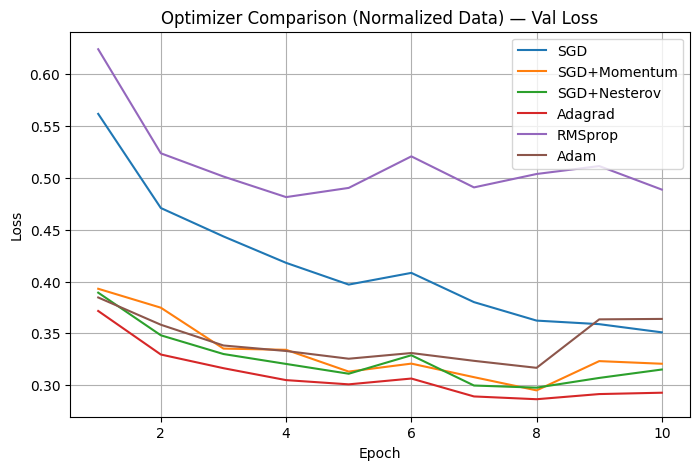

In [11]:
lr_sgd_family = 0.01
lr_adam = 0.001

optimizers_cfg = [
    ("SGD",                    lambda p: torch.optim.SGD(p, lr=lr_sgd_family)),
    ("SGD+Momentum",           lambda p: torch.optim.SGD(p, lr=lr_sgd_family, momentum=0.9)),
    ("SGD+Nesterov",           lambda p: torch.optim.SGD(p, lr=lr_sgd_family, momentum=0.9, nesterov=True)),
    ("Adagrad",                lambda p: torch.optim.Adagrad(p, lr=lr_sgd_family)),
    ("RMSprop",                lambda p: torch.optim.RMSprop(p, lr=lr_sgd_family)),
    ("Adam",                   lambda p: torch.optim.Adam(p, lr=lr_adam)),
]

loss_curves = {}
val_curves  = {}
for name, opt_factory in optimizers_cfg:
    torch.manual_seed(seed)
    model = MLP().to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = opt_factory(model.parameters())
    epoch_losses, epoch_val_losses = [], []
    for epoch in range(epochs):
        model.train()
        loss_sum, count = 0.0, 0
        for x, y in norm_train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * y.size(0)
            count    += y.size(0)
        epoch_losses.append(loss_sum / count)
        model.eval()
        vloss_sum, vcount = 0.0, 0
        with torch.no_grad():
            for x, y in norm_val_loader:
                x, y = x.to(device), y.to(device)
                vloss_sum += criterion(model(x), y).item() * y.size(0)
                vcount    += y.size(0)
        epoch_val_losses.append(vloss_sum / vcount)
    loss_curves[name] = epoch_losses
    val_curves[name]  = epoch_val_losses

# plt.figure(figsize=(10,6))
# for name in loss_curves.keys():
#     plt.plot(range(1, epochs+1), loss_curves[name], label=f"{name} (Train)")
#     plt.plot(range(1, epochs+1), val_curves[name],  linestyle="--", label=f"{name} (Val)")
# plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Optimizer Comparison on Normalized Data (Train & Val)")
# plt.grid(True); plt.legend(ncol=2); plt.show()
# train 까지 실행결과 RMSprop의 train으로 인해 loss 정확히 구분하기 힘들기에 validation만을 이용해 진행

plt.figure(figsize=(8,5))
for name, losses in val_curves.items():
    plt.plot(range(1, epochs+1), losses, label=name)
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Optimizer Comparison (Normalized Data) — Val Loss")
plt.grid(True); plt.legend(); plt.show()

In [15]:
epochs=20
torch.manual_seed(seed)
model = MLP().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adagrad(model.parameters())

train_losses_no = []
val_losses_no   = []
val_accs_no     = []

print("=== No Dropout ===")
for epoch in range(epochs):
    model.train()
    loss_sum, cnt = 0.0, 0
    for x, y in norm_train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * y.size(0)
        cnt     += y.size(0)
    train_losses_no.append(loss_sum / cnt)

    model.eval()
    vloss_sum, vcnt, vcorrect = 0.0, 0, 0
    with torch.no_grad():
        for x, y in norm_val_loader:
            x, y = x.to(device), y.to(device)
            vloss_sum += criterion(model(x), y).item() * y.size(0)
            vcnt      += y.size(0)
            vcorrect  += (model(x).argmax(1) == y).sum().item()
    val_losses_no.append(vloss_sum / vcnt)
    val_accs_no.append(vcorrect / vcnt)
    print(f"Epoch {epoch:02d} | train_loss={train_losses_no[-1]:.4f} | val_loss={val_losses_no[-1]:.4f} | val_acc={val_accs_no[-1]*100:5.2f}%")

=== No Dropout ===
Epoch 00 | train_loss=0.4676 | val_loss=0.3716 | val_acc=86.44%
Epoch 01 | train_loss=0.3266 | val_loss=0.3296 | val_acc=87.67%
Epoch 02 | train_loss=0.2910 | val_loss=0.3164 | val_acc=88.21%
Epoch 03 | train_loss=0.2687 | val_loss=0.3049 | val_acc=88.74%
Epoch 04 | train_loss=0.2503 | val_loss=0.3008 | val_acc=89.21%
Epoch 05 | train_loss=0.2340 | val_loss=0.3064 | val_acc=88.74%
Epoch 06 | train_loss=0.2220 | val_loss=0.2891 | val_acc=89.46%
Epoch 07 | train_loss=0.2100 | val_loss=0.2864 | val_acc=89.71%
Epoch 08 | train_loss=0.1989 | val_loss=0.2914 | val_acc=89.39%
Epoch 09 | train_loss=0.1886 | val_loss=0.2927 | val_acc=89.50%
Epoch 10 | train_loss=0.1788 | val_loss=0.2918 | val_acc=89.94%
Epoch 11 | train_loss=0.1701 | val_loss=0.2967 | val_acc=89.91%
Epoch 12 | train_loss=0.1609 | val_loss=0.2941 | val_acc=89.76%
Epoch 13 | train_loss=0.1533 | val_loss=0.2933 | val_acc=90.11%
Epoch 14 | train_loss=0.1460 | val_loss=0.3021 | val_acc=89.70%
Epoch 15 | train_loss


=== With Dropout ===
Epoch 00 | train_loss=0.5714 | val_loss=0.4109 | val_acc=84.77%
Epoch 01 | train_loss=0.4281 | val_loss=0.3736 | val_acc=86.14%
Epoch 02 | train_loss=0.3915 | val_loss=0.3502 | val_acc=87.07%
Epoch 03 | train_loss=0.3692 | val_loss=0.3429 | val_acc=87.29%
Epoch 04 | train_loss=0.3547 | val_loss=0.3361 | val_acc=87.66%
Epoch 05 | train_loss=0.3403 | val_loss=0.3306 | val_acc=88.01%
Epoch 06 | train_loss=0.3322 | val_loss=0.3201 | val_acc=88.21%
Epoch 07 | train_loss=0.3229 | val_loss=0.3150 | val_acc=88.54%
Epoch 08 | train_loss=0.3160 | val_loss=0.3133 | val_acc=88.23%
Epoch 09 | train_loss=0.3084 | val_loss=0.3114 | val_acc=88.29%
Epoch 10 | train_loss=0.3030 | val_loss=0.3047 | val_acc=88.87%
Epoch 11 | train_loss=0.2954 | val_loss=0.3016 | val_acc=89.04%
Epoch 12 | train_loss=0.2920 | val_loss=0.3020 | val_acc=89.19%
Epoch 13 | train_loss=0.2880 | val_loss=0.2980 | val_acc=89.39%
Epoch 14 | train_loss=0.2814 | val_loss=0.3017 | val_acc=89.07%
Epoch 15 | train_l

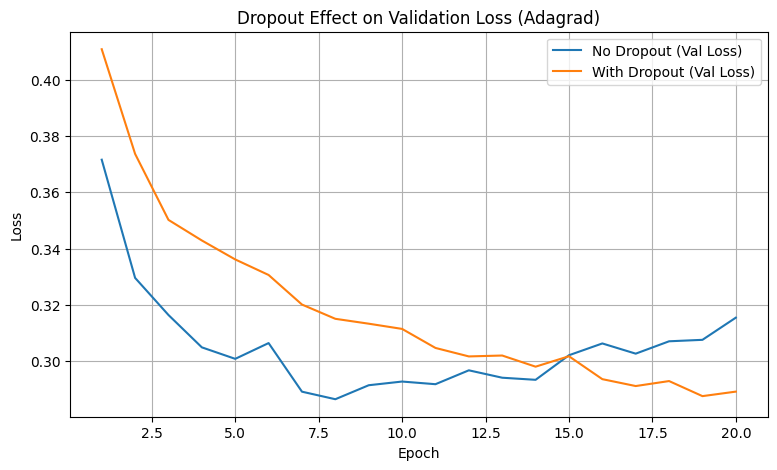

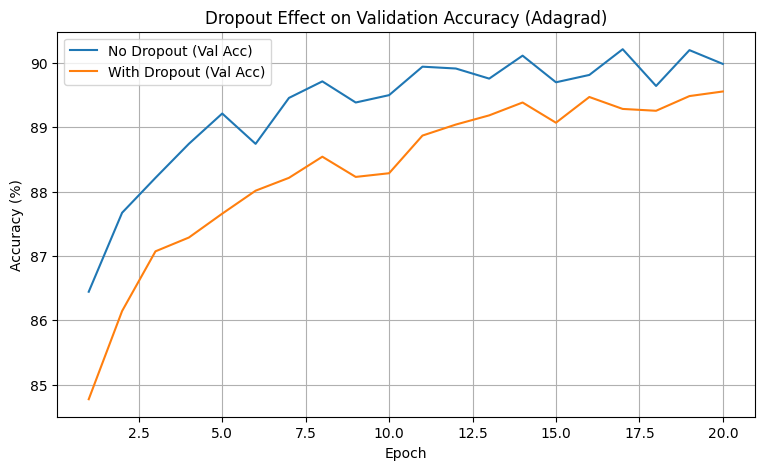

In [16]:
epochs=20
class MLP_Dropout(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(),
            nn.Linear(512, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(),
            nn.Linear(512, 10)
        )
    def forward(self, x):
        return self.net(x)

torch.manual_seed(seed)
model = MLP_Dropout().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adagrad(model.parameters())

train_losses_do = []
val_losses_do   = []
val_accs_do     = []

print("\n=== With Dropout ===")
for epoch in range(epochs):
    model.train()
    loss_sum, cnt = 0.0, 0
    for x, y in norm_train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * y.size(0)
        cnt     += y.size(0)
    train_losses_do.append(loss_sum / cnt)

    model.eval()
    vloss_sum, vcnt, vcorrect = 0.0, 0, 0
    with torch.no_grad():
        for x, y in norm_val_loader:
            x, y = x.to(device), y.to(device)
            vloss_sum += criterion(model(x), y).item() * y.size(0)
            vcnt      += y.size(0)
            vcorrect  += (model(x).argmax(1) == y).sum().item()
    val_losses_do.append(vloss_sum / vcnt)
    val_accs_do.append(vcorrect / vcnt)
    print(f"Epoch {epoch:02d} | train_loss={train_losses_do[-1]:.4f} | val_loss={val_losses_do[-1]:.4f} | val_acc={val_accs_do[-1]*100:5.2f}%")


plt.figure(figsize=(19,5))
plt.plot(range(1, epochs+1), val_losses_no, label="No Dropout (Val Loss)")
plt.plot(range(1, epochs+1), val_losses_do, label="With Dropout (Val Loss)")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Dropout Effect on Validation Loss (Adagrad)")
plt.grid(True); plt.legend(); plt.show()

plt.figure(figsize=(19,5))
plt.plot(range(1, epochs+1), [a*100 for a in val_accs_no], label="No Dropout (Val Acc)")
plt.plot(range(1, epochs+1), [a*100 for a in val_accs_do], label="With Dropout (Val Acc)")
plt.xlabel("Epoch"); plt.ylabel("Accuracy (%)"); plt.title("Dropout Effect on Validation Accuracy (Adagrad)")
plt.grid(True); plt.legend(); plt.show()


=== BatchNorm Only (No Dropout) ===
Epoch 00 | train_loss=0.4274 | val_loss=0.3456 | val_acc=87.29%
Epoch 01 | train_loss=0.3133 | val_loss=0.3148 | val_acc=88.46%
Epoch 02 | train_loss=0.2724 | val_loss=0.3002 | val_acc=89.00%
Epoch 03 | train_loss=0.2467 | val_loss=0.2844 | val_acc=89.69%
Epoch 04 | train_loss=0.2238 | val_loss=0.2834 | val_acc=89.60%
Epoch 05 | train_loss=0.2054 | val_loss=0.2916 | val_acc=89.31%
Epoch 06 | train_loss=0.1887 | val_loss=0.2712 | val_acc=90.24%
Epoch 07 | train_loss=0.1741 | val_loss=0.2755 | val_acc=90.16%
Epoch 08 | train_loss=0.1608 | val_loss=0.2809 | val_acc=90.30%
Epoch 09 | train_loss=0.1482 | val_loss=0.2837 | val_acc=90.39%
Epoch 10 | train_loss=0.1372 | val_loss=0.2944 | val_acc=90.51%
Epoch 11 | train_loss=0.1273 | val_loss=0.3011 | val_acc=89.99%
Epoch 12 | train_loss=0.1162 | val_loss=0.3039 | val_acc=89.86%
Epoch 13 | train_loss=0.1087 | val_loss=0.3014 | val_acc=90.09%
Epoch 14 | train_loss=0.1019 | val_loss=0.3162 | val_acc=89.71%
Epo

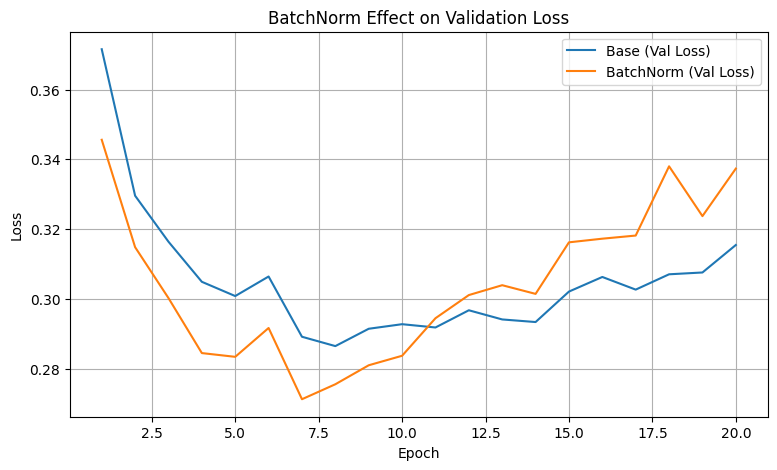

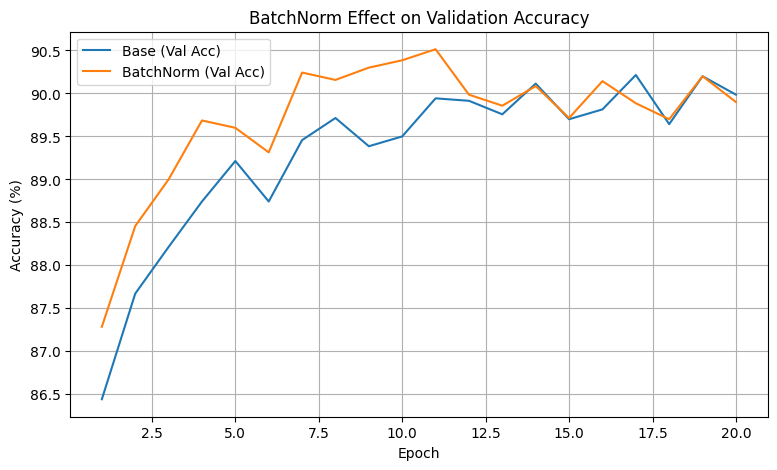

In [17]:
class MLP_BN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 10)
        )
    def forward(self, x):
        return self.net(x)

torch.manual_seed(seed)
model = MLP_BN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adagrad(model.parameters())

train_losses_bn = []
val_losses_bn   = []
val_accs_bn     = []

print("\n=== BatchNorm Only ===")
for epoch in range(epochs):
    model.train()
    loss_sum, cnt = 0.0, 0
    for x, y in norm_train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * y.size(0)
        cnt     += y.size(0)
    train_losses_bn.append(loss_sum / cnt)

    model.eval()
    vloss_sum, vcnt, vcorrect = 0.0, 0, 0
    with torch.no_grad():
        for x, y in norm_val_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            vloss_sum += criterion(out, y).item() * y.size(0)
            vcnt      += y.size(0)
            vcorrect  += (out.argmax(1) == y).sum().item()
    val_losses_bn.append(vloss_sum / vcnt)
    val_accs_bn.append(vcorrect / vcnt)
    print(f"Epoch {epoch:02d} | train_loss={train_losses_bn[-1]:.4f} | val_loss={val_losses_bn[-1]:.4f} | val_acc={val_accs_bn[-1]*100:5.2f}%")
import matplotlib.pyplot as plt

plt.figure(figsize=(9,5))
plt.plot(range(1, epochs+1), val_losses_no, label="Base (Val Loss)")
plt.plot(range(1, epochs+1), val_losses_bn, label="BatchNorm (Val Loss)")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("BatchNorm Effect on Validation Loss")
plt.grid(True); plt.legend(); plt.show()

plt.figure(figsize=(9,5))
plt.plot(range(1, epochs+1), [a*100 for a in val_accs_no], label="Base (Val Acc)")
plt.plot(range(1, epochs+1), [a*100 for a in val_accs_bn], label="BatchNorm (Val Acc)")
plt.xlabel("Epoch"); plt.ylabel("Accuracy (%)"); plt.title("BatchNorm Effect on Validation Accuracy")
plt.grid(True); plt.legend(); plt.show()

In [18]:
epochs = 40
batch_size_final = 256

class MLP_BN(nn.Module):
    def __init__(self, p=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 10)
        )
    def forward(self, x):
        return self.net(x)

# ===== 학습 (Adagrad + 얼리 스톱 옵션) =====
torch.manual_seed(seed)
model = MLP_BN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adagrad(model.parameters())  # lr=0.01 (default)

train_losses, val_losses, val_accs = [], [], []
best_val = float("inf")
best_state = None
patience, wait = 5, 0

print(f"== Train BN, Adagrad, bs={batch_size_final}, epochs={epochs} ==")
for epoch in range(epochs):
    # train
    model.train()
    loss_sum, cnt = 0.0, 0
    for x, y in norm_train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * y.size(0)
        cnt     += y.size(0)
    train_losses.append(loss_sum / cnt)

    # val
    model.eval()
    vloss_sum, vcnt, vcorrect = 0.0, 0, 0
    with torch.no_grad():
        for x, y in norm_val_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            vloss_sum += criterion(out, y).item() * y.size(0)
            vcnt      += y.size(0)
            vcorrect  += (out.argmax(1) == y).sum().item()
    val_loss = vloss_sum / vcnt
    val_acc  = vcorrect / vcnt
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    # 로그
    print(f"[Epoch {epoch:02d}] train_loss={train_losses[-1]:.4f} | val_loss={val_loss:.4f} | val_acc={val_acc*100:5.2f}%")

    # Early Stopping(선택)
    if val_loss < best_val:
        best_val = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            print(f"Early stopping at epoch {epoch} (no improvement for {patience} epochs).")
            break

# 베스트 체크포인트 로드
if best_state is not None:
    model.load_state_dict(best_state)

# ===== Test 성능 =====
model.eval()
with torch.no_grad():
    tcorrect, tcnt = 0, 0
    for x, y in norm_test_loader:
        x, y = x.to(device), y.to(device)
        pred = model(x).argmax(1)
        tcorrect += (pred == y).sum().item()
        tcnt     += y.size(0)
test_acc = tcorrect / tcnt
print(f"\n=== FINAL Test Accuracy (BN+Drop, Adagrad) : {test_acc*100:5.2f}% ===")

== Train BN, Adagrad, bs=256, epochs=40 ==
[Epoch 00] train_loss=0.4274 | val_loss=0.3456 | val_acc=87.29%
[Epoch 01] train_loss=0.3133 | val_loss=0.3148 | val_acc=88.46%
[Epoch 02] train_loss=0.2724 | val_loss=0.3002 | val_acc=89.00%
[Epoch 03] train_loss=0.2467 | val_loss=0.2844 | val_acc=89.69%
[Epoch 04] train_loss=0.2238 | val_loss=0.2834 | val_acc=89.60%
[Epoch 05] train_loss=0.2054 | val_loss=0.2916 | val_acc=89.31%
[Epoch 06] train_loss=0.1887 | val_loss=0.2712 | val_acc=90.24%
[Epoch 07] train_loss=0.1741 | val_loss=0.2755 | val_acc=90.16%
[Epoch 08] train_loss=0.1608 | val_loss=0.2809 | val_acc=90.30%
[Epoch 09] train_loss=0.1482 | val_loss=0.2837 | val_acc=90.39%
[Epoch 10] train_loss=0.1372 | val_loss=0.2944 | val_acc=90.51%
[Epoch 11] train_loss=0.1273 | val_loss=0.3011 | val_acc=89.99%
Early stopping at epoch 11 (no improvement for 5 epochs).

=== FINAL Test Accuracy (BN+Drop, Adagrad) : 90.14% ===
